# 04 - LightGCN parameter study

**Owner:** Member 3
**Task:** Vary the number of layers (0-4), embedding dimension, learning rate and L2 for LightGCN on KuaiRand-Pure and KuaiRec. Layer 0 is the MF-equivalent control. Select on validation Recall@20 only. Figure: Recall@20 vs. number of layers on the biased and the unbiased test (over-smoothing curve).
**Inputs:** src/data/, src/models/, src/training/
**Outputs:** results/04_lightgcn_parameters_<dataset>.json (every run), results/04_layers.png

After running: save the numbers to `results/`, append an entry to `LOG.md`, and write the matching report section.

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..", "src")))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import data
import models
import training
import inference

SEEDS = [0, 1, 2]
RESULTS_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "results"))
os.makedirs(RESULTS_DIR, exist_ok=True)


## Experiments


### Grid

Selection grid of 8 configurations, the same count as notebook 03's BPR-MF grid (fairness rule 2): layers 2/3 x
dimension 64/128 x L2 1e-5/1e-4, with the learning rate fixed to 0.001 — the value BPR-MF selected — so the
learning rate is not a second difference between the models. On top of the grid, 8 sensitivity runs at learning
rate 0.005 (every one ranked strictly lower on validation, so they are not selection budget), and the layer
study adding layers 0, 1 and 4 at the best configuration (2 and 3 are in the grid); layer 0 is the
MF-equivalent control. Runs are cached in `results/04_lightgcn_parameters_<dataset>.json`; standalone:

```bash
python src/experiments/run_grid.py 04 kuairand 04 kuairec
```

In [2]:
from experiments.run_grid import layer_curve, merge_runs, run_grid, run_layers, select_best

DATASETS = ("kuairand", "kuairec")
for name in DATASETS:
    run_grid("04", name)
    run_layers(name)
runs = merge_runs("04", DATASETS)
print(len(runs), "runs cached")

38 runs cached


### Validation table

Selection-grid runs first, then the lr=0.005 sensitivity runs and their validation Recall@20, seed 0. The
unbiased test is never used to select (fairness rule 9).

In [3]:
rows = []
for key, r in runs.items():
    if r["phase"] == "layers":
        continue
    c = r["cfg"]
    rows.append(dict(dataset=r["dataset"], phase=r["phase"], layers=c["layers"], dim=c["dim"], lr=c["lr"], reg=c["reg"],
                     val_recall=r["val_recall"], test_recall=r["test"]["recall"],
                     unbiased_recall=r["test_unbiased"]["recall"], best_epoch=r["best_epoch"],
                     time_s=round(r["train_time"])))
pd.DataFrame(rows).sort_values(["dataset", "phase", "val_recall"], ascending=[True, True, False]).reset_index(drop=True)

,dataset,phase,layers,dim,lr,reg,val_recall,test_recall,unbiased_recall,best_epoch,time_s
0,kuairand,grid,3,128,0.001,0.00010,0.210858,0.217922,0.006318,95,580
1,kuairand,grid,2,128,0.001,0.00010,0.209774,0.215764,0.006304,90,464
2,kuairand,grid,3,128,0.001,0.00001,0.209433,0.216429,0.006463,100,576
3,kuairand,grid,2,128,0.001,0.00001,0.207652,0.212687,0.006312,90,465
4,kuairand,grid,2,64,0.001,0.00010,0.203065,0.209115,0.006359,100,318
5,kuairand,grid,2,64,0.001,0.00001,0.201658,0.208107,0.006446,100,321
6,kuairand,grid,3,64,0.001,0.00010,0.199271,0.205091,0.006442,100,386
7,kuairand,grid,3,64,0.001,0.00001,0.198619,0.204885,0.006272,100,385
8,kuairand,sensitivity,3,128,0.005,0.00010,0.202909,0.208182,0.006635,35,294
9,kuairand,sensitivity,3,64,0.005,0.00010,0.202743,0.209581,0.006367,35,235


### Selected setting

Best validation Recall@20 per dataset; notebooks 05, 06 and 08 use these settings.

In [4]:
selected = {name: select_best(runs, name) for name in DATASETS}
for name, s in selected.items():
    c = s["cfg"]
    print(f"{name}: layers={c['layers']} dim={c['dim']} lr={c['lr']} reg={c['reg']}  "
          f"val_recall={s['val_recall']:.4f} (epoch {s['best_epoch']}), "
          f"test_recall={s['test']['recall']:.4f}, unbiased_recall={s['test_unbiased']['recall']:.4f}")

kuairand: layers=3 dim=128 lr=0.001 reg=0.0001  val_recall=0.2109 (epoch 95), test_recall=0.2179, unbiased_recall=0.0063
kuairec: layers=3 dim=128 lr=0.001 reg=0.0001  val_recall=0.1279 (epoch 100), test_recall=0.1255, unbiased_recall=0.1634


### Over-smoothing curve

Recall@20 by number of propagation layers at the selected configuration, on the biased and the unbiased test. Layer 0 propagates nothing: the same embeddings and BPR loss as BPR-MF, so the difference at layer 0 is the training-loop control, and how each curve moves away from it is what propagation adds on each test.

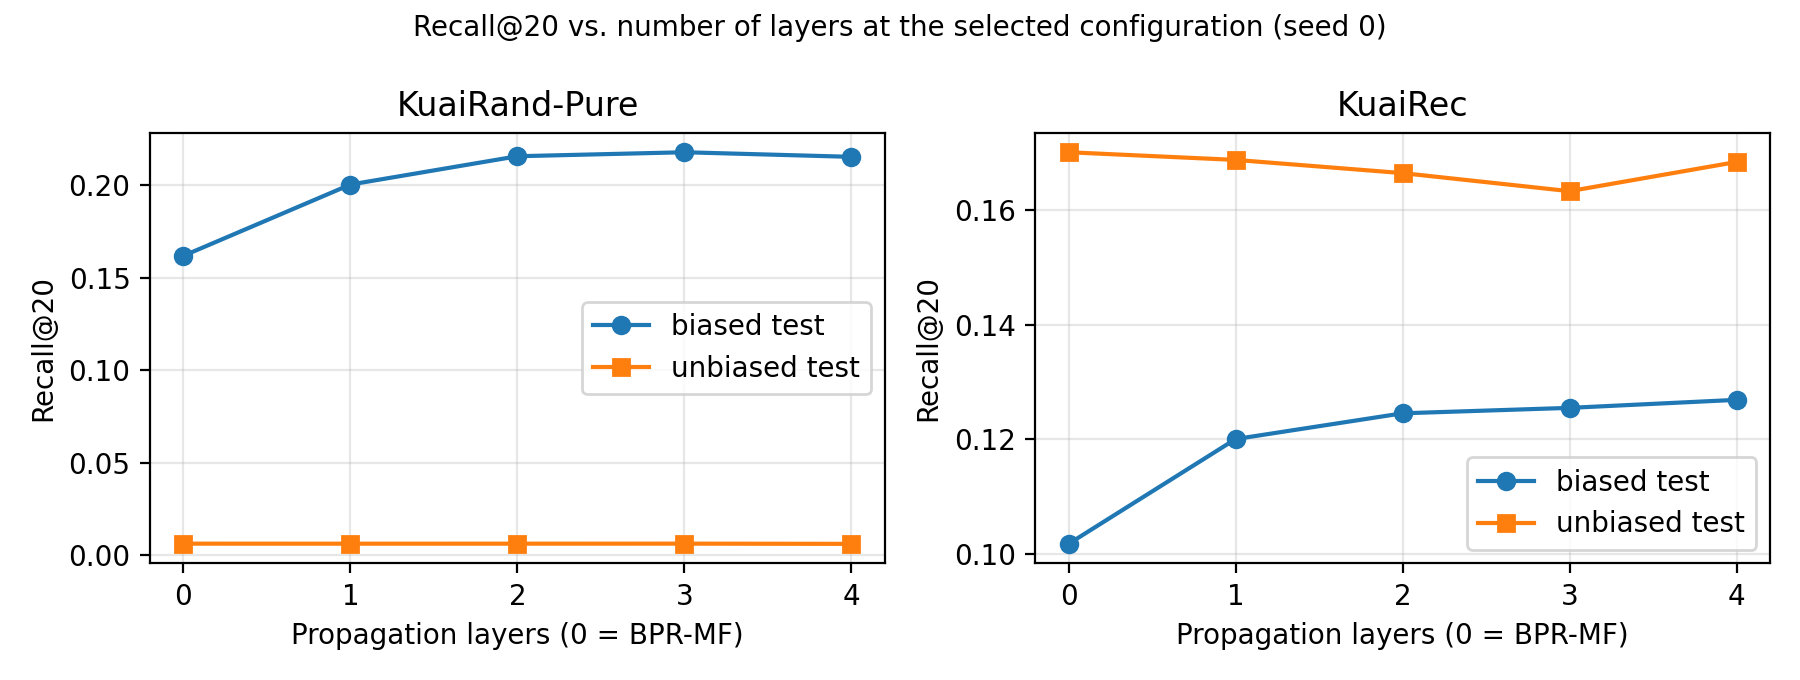

In [5]:
LABELS = {"kuairand": "KuaiRand-Pure", "kuairec": "KuaiRec"}
fig, axes = plt.subplots(1, len(DATASETS), figsize=(4.5 * len(DATASETS), 3.4), squeeze=False)
for ax, name in zip(axes[0], DATASETS):
    c = pd.DataFrame(layer_curve(name)).dropna(subset=["test_recall"])
    ax.plot(c.layers, c.test_recall, marker="o", label="biased test")
    ax.plot(c.layers, c.unbiased_recall, marker="s", label="unbiased test")
    ax.set(xlabel="Propagation layers (0 = BPR-MF)", ylabel="Recall@20", title=LABELS[name], xticks=c.layers)
    ax.grid(alpha=0.3)
    ax.legend()
fig.suptitle("Recall@20 vs. number of layers at the selected configuration (seed 0)", fontsize=10)
fig.tight_layout()
from IPython.display import Image
fig.savefig(os.path.join(RESULTS_DIR, "04_layers.png"), dpi=200, metadata={"Software": None})
plt.close(fig)  # display the saved file instead: the inline copy would embed matplotlib's web address
Image(filename=os.path.join(RESULTS_DIR, "04_layers.png"))

In [6]:
pd.concat([pd.DataFrame(layer_curve(name)).assign(dataset=name) for name in DATASETS])

,layers,dim,lr,reg,val_recall,test_recall,unbiased_recall,dataset
0,0,128,0.001,0.0001,0.157568,0.161952,0.006309,kuairand
1,1,128,0.001,0.0001,0.194023,0.200464,0.006293,kuairand
2,2,128,0.001,0.0001,0.209774,0.215764,0.006304,kuairand
3,3,128,0.001,0.0001,0.210858,0.217922,0.006318,kuairand
4,4,128,0.001,0.0001,0.208354,0.215436,0.006199,kuairand
0,0,128,0.001,0.0001,0.102077,0.101719,0.170173,kuairec
1,1,128,0.001,0.0001,0.120647,0.120036,0.168833,kuairec
2,2,128,0.001,0.0001,0.126447,0.124541,0.166526,kuairec
3,3,128,0.001,0.0001,0.127869,0.125491,0.163369,kuairec
4,4,128,0.001,0.0001,0.127231,0.126893,0.168476,kuairec
